# Actividad 05 · Clustering, PCA y NMF

**Universidad Nacional del Altiplano · Ingeniería de Sistemas · Aprendizaje de Máquina, IX ciclo, grupo B**  
**Docente:** Ing. Mayenka Fernandez Chambi  
**Integrantes:** Cunurana Calderon Cristian Junior · Llusca Surco Miguel Angel · Yucra Mendoza Maria Vanesa

## Objetivo
Comprender y comparar tres aplicaciones: clustering jerárquico de textos, reconocimiento facial clásico con Eigenfaces y recomendación temática con NMF.

| Caso | Responsable |
|---|---|
| 01 · Clustering jerárquico y 20 Newsgroups | Cunurana Calderon Cristian Junior |
| 02 · PCA y Eigenfaces | Llusca Surco Miguel Angel |
| 03 · NMF y recomendación | Yucra Mendoza Maria Vanesa |

La distribución sigue el orden de integrantes del archivo del curso, pues la consigna no asigna casos. Semilla fija: **42**. Las etiquetas de 20 Newsgroups se reservan para evaluación externa; la proyección bidimensional es solo ilustrativa.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import fetch_20newsgroups, fetch_olivetti_faces
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA, NMF
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
 adjusted_rand_score, normalized_mutual_info_score, accuracy_score, precision_score,
 recall_score, f1_score, confusion_matrix, mean_squared_error)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.sparse import csr_matrix
from IPython.display import display

SEED=42
ROOT=Path.cwd()
RES=ROOT/'resultados'
for q in ['01_clustering_jerarquico/figuras','02_pca_eigenfaces/figuras','03_nmf_recomendacion/figuras']:
    (RES/q).mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':300,'font.size':10,'axes.titlesize':13,'axes.labelsize':10})
sns.set_theme(style='whitegrid',palette='deep')
def savefig(path):
    plt.tight_layout(); plt.savefig(path,bbox_inches='tight',dpi=300); plt.show(); plt.close()
print('Python listo | semilla',SEED)

Python listo | semilla 42


## Caso 01 · Clustering jerárquico de documentos
**Responsable:** Cunurana Calderon Cristian Junior

20 Newsgroups reúne mensajes de 20 foros Usenet distribuidos en categorías temáticas. Se descargan los subconjuntos oficiales de entrenamiento y prueba de scikit-learn; la comparación no usa etiquetas al ajustar. La eliminación de encabezados, firmas y citas reduce señales accidentales. TF-IDF limita vocabulario a 3 000 términos; TruncatedSVD produce una representación compacta, y la normalización permite comparar documentos con longitudes distintas.

Se conserva una muestra estratificada de 12 mensajes por categoría (240 en total), adecuada para comparar cuatro métodos con clustering aglomerativo cuadrático. La distancia euclidiana es común a todos; Ward es compatible únicamente con ella. Silhouette, Calinski–Harabasz y Davies–Bouldin son internas; ARI y NMI requieren etiquetas y se usan solo después del ajuste.

Train: 11,314 documentos; test: 7,532; categorías: 20


,categoría,documentos_train
0,alt.atheism,480
1,comp.graphics,584
2,comp.os.ms-windows.misc,591
3,comp.sys.ibm.pc.hardware,590
4,comp.sys.mac.hardware,578
5,comp.windows.x,593
6,misc.forsale,585
7,rec.autos,594
8,rec.motorcycles,598
9,rec.sport.baseball,597


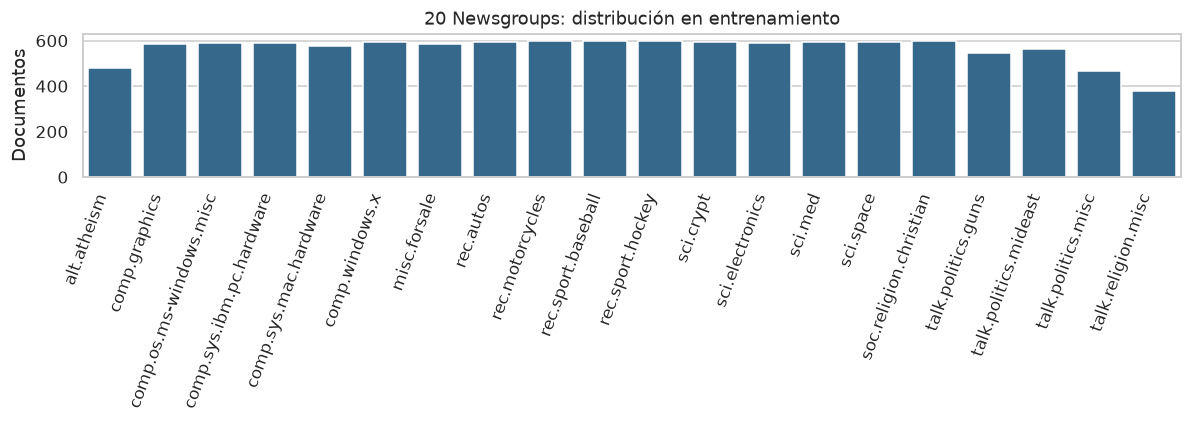

Ejemplo (recortado): Don't be so sure. Look what happened to Japanese citizens in the US during World War II. If you're prepared to say "Let's round these people up and stick them in a concentration camp without


TF-IDF: 11314 × 3000 dispersa; experimento: 240 documentos × 80 componentes SVD.


In [2]:
news_train=fetch_20newsgroups(subset='train',remove=('headers','footers','quotes'))
news_test=fetch_20newsgroups(subset='test',remove=('headers','footers','quotes'))
texts=np.asarray(news_train.data,dtype=object); y=np.asarray(news_train.target); names=np.asarray(news_train.target_names)
dist=pd.Series(y).value_counts().sort_index()
print(f'Train: {len(texts):,} documentos; test: {len(news_test.data):,}; categorías: {len(names)}')
display(pd.DataFrame({'categoría':names,'documentos_train':dist.values}))
plt.figure(figsize=(11,4)); sns.barplot(x=names,y=dist.values,color='#276A9B'); plt.xticks(rotation=70,ha='right'); plt.ylabel('Documentos'); plt.title('20 Newsgroups: distribución en entrenamiento'); savefig(RES/'01_clustering_jerarquico/figuras/distribucion.png')
print('Ejemplo (recortado):', ' '.join(texts[np.flatnonzero(y==0)[0]].split()[:35]))
vec1=TfidfVectorizer(stop_words='english',max_features=3000,min_df=3,max_df=.90,sublinear_tf=True)
Xtf=vec1.fit_transform(texts)
svd=TruncatedSVD(n_components=80,random_state=SEED)
Xall=normalize(svd.fit_transform(Xtf))
rng=np.random.default_rng(SEED)
idx=np.concatenate([rng.choice(np.flatnonzero(y==k),size=min(12,np.sum(y==k)),replace=False) for k in range(len(names))])
idx=np.sort(idx); X=Xall[idx]; ys=y[idx]
print(f'TF-IDF: {Xtf.shape[0]} × {Xtf.shape[1]} dispersa; experimento: {len(idx)} documentos × 80 componentes SVD.')

,linkage,clusters,silhouette,calinski_harabasz,davies_bouldin,ARI,NMI,segundos
0,ward,20,0.0707,4.7582,2.6194,0.1356,0.4702,0.0024
1,complete,20,0.0523,4.1711,2.7461,0.1359,0.4624,0.0014
2,average,20,0.0542,3.6925,2.3144,0.1205,0.4444,0.0020
3,single,20,-0.1196,1.0503,0.9721,-0.0001,0.1369,0.0012


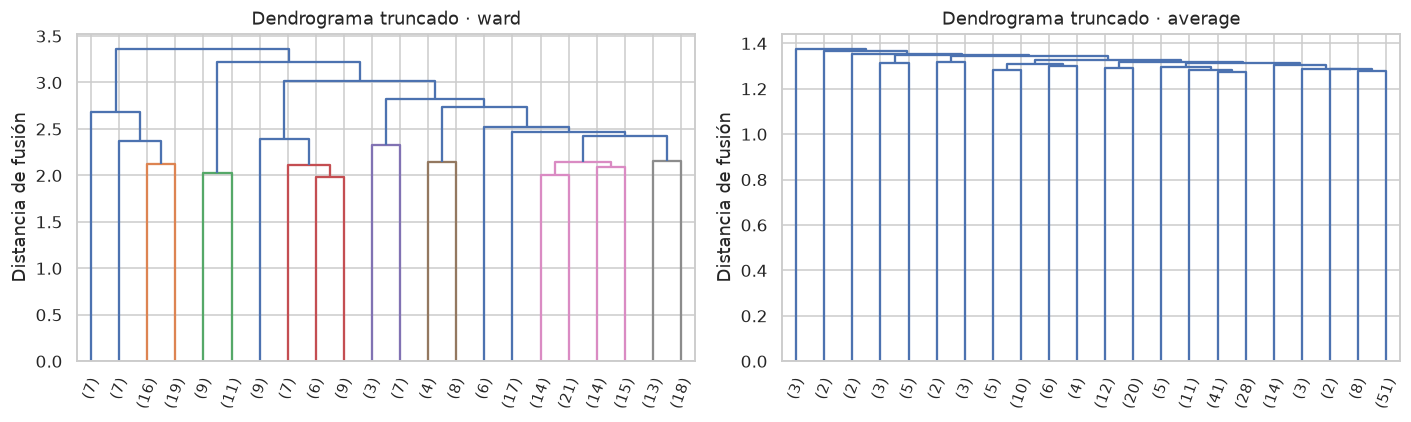

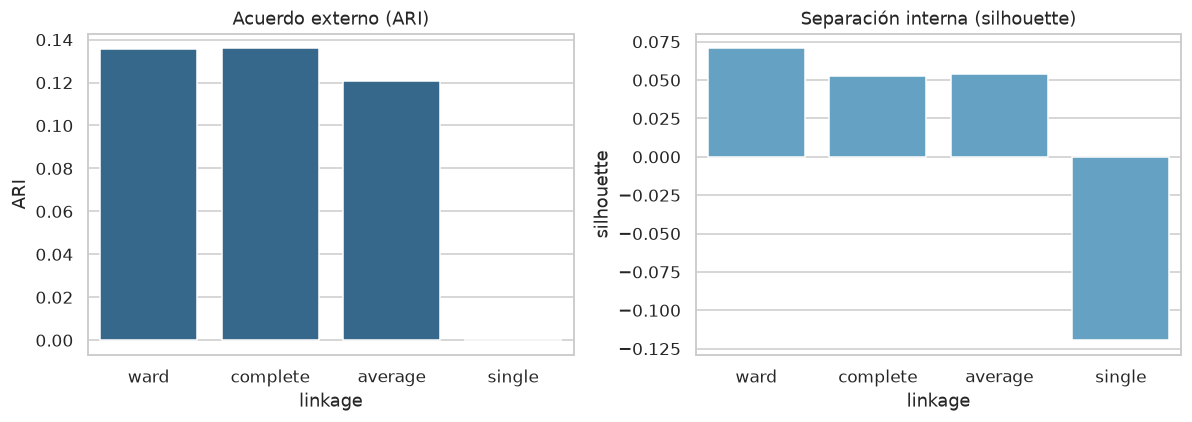

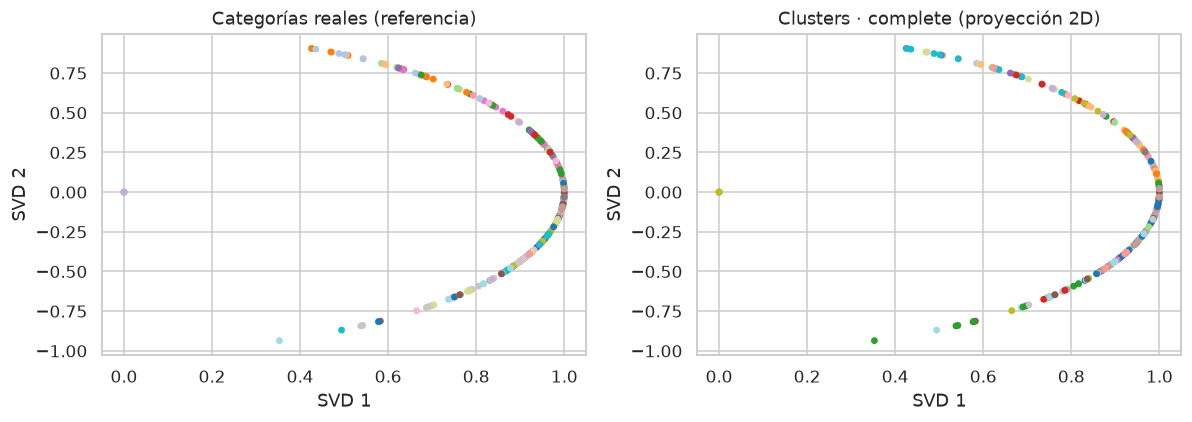

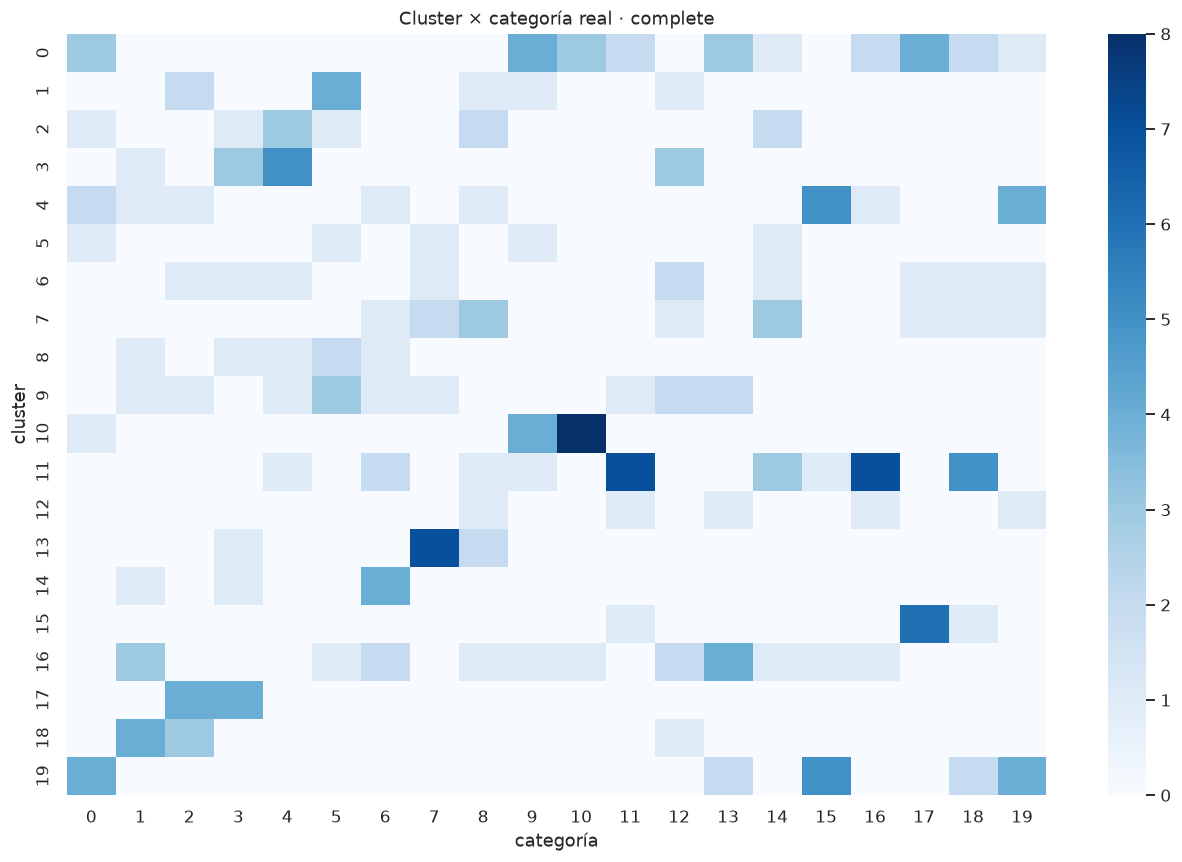

,cluster,n,palabras
0,0,25,"years, year, probably, sp, think, quite, peopl..."
1,1,9,"window, timing, got, windows, actually, bell, ..."
2,2,10,"list, meg, simms, memory, like, stuff, does, i..."
3,3,12,"disk, drive, know, software, mhz, apple, acces..."
4,4,16,"god, love, don, just, christian, mean, christ, ll"
5,5,5,"post, program, april, research, feel, soul, ad..."
6,6,10,"read, article, bmw, new, homosexual, pc, kores..."
7,7,13,"bike, honda, 88, earth, left, north, road, job"
8,8,6,"thanks, advance, monitor, map, drawing, patch,..."
9,9,13,"ve, mail, help, code, leave, message, informat..."


categoría,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
cluster,,,,,,,,,,,,,,,,,,,,
0,3,0,0,0,0,0,0,0,0,4,3,2,0,3,1,0,2,4,2,1
1,0,0,2,0,0,4,0,0,1,1,0,0,1,0,0,0,0,0,0,0
2,1,0,0,1,3,1,0,0,2,0,0,0,0,0,2,0,0,0,0,0
3,0,1,0,3,5,0,0,0,0,0,0,0,3,0,0,0,0,0,0,0
4,2,1,1,0,0,0,1,0,1,0,0,0,0,0,0,5,1,0,0,4


In [3]:
rows=[]; labels_by={}
for method in ['ward','complete','average','single']:
    t0=time.perf_counter()
    model=AgglomerativeClustering(n_clusters=20,linkage=method,metric='euclidean')
    lab=model.fit_predict(X); elapsed=time.perf_counter()-t0; labels_by[method]=lab
    rows.append({'linkage':method,'clusters':len(np.unique(lab)),'silhouette':silhouette_score(X,lab),
      'calinski_harabasz':calinski_harabasz_score(X,lab),'davies_bouldin':davies_bouldin_score(X,lab),
      'ARI':adjusted_rand_score(ys,lab),'NMI':normalized_mutual_info_score(ys,lab),'segundos':elapsed})
cldf=pd.DataFrame(rows); display(cldf.round(4)); cldf.to_csv(RES/'01_clustering_jerarquico/metricas.csv',index=False)
# Dendrogramas ilustrativos en la misma muestra (distancias euclidianas)
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax,method in zip(axs,['ward','average']):
    Z=linkage(X,method=method,metric='euclidean'); dendrogram(Z,truncate_mode='lastp',p=22,show_leaf_counts=True,leaf_rotation=70,ax=ax)
    ax.set_title(f'Dendrograma truncado · {method}'); ax.set_ylabel('Distancia de fusión')
savefig(RES/'01_clustering_jerarquico/figuras/dendrogramas.png')
# Métricas por linkage
fig,axs=plt.subplots(1,2,figsize=(11,4)); sns.barplot(data=cldf,x='linkage',y='ARI',ax=axs[0],color='#276A9B'); sns.barplot(data=cldf,x='linkage',y='silhouette',ax=axs[1],color='#55A6D1'); axs[0].set_title('Acuerdo externo (ARI)'); axs[1].set_title('Separación interna (silhouette)'); savefig(RES/'01_clustering_jerarquico/figuras/comparacion_metricas.png')
# Proyección SVD de 2D solo para vista
X2=normalize(TruncatedSVD(n_components=2,random_state=SEED).fit_transform(Xtf[idx]))
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].scatter(X2[:,0],X2[:,1],c=ys,s=12,cmap='tab20'); axs[0].set_title('Categorías reales (referencia)')
best=cldf.sort_values(['ARI','NMI'],ascending=False).iloc[0]['linkage']; axs[1].scatter(X2[:,0],X2[:,1],c=labels_by[best],s=12,cmap='tab20'); axs[1].set_title(f'Clusters · {best} (proyección 2D)')
for ax in axs: ax.set_xlabel('SVD 1'); ax.set_ylabel('SVD 2')
savefig(RES/'01_clustering_jerarquico/figuras/proyeccion_clusters.png')
# Contingencia + palabras destacadas por grupo
bestlab=labels_by[best]; cont=pd.crosstab(pd.Series(bestlab,name='cluster'),pd.Series(ys,name='categoría'))
cont.to_csv(RES/'01_clustering_jerarquico/contingencia.csv')
plt.figure(figsize=(12,8)); sns.heatmap(cont,cmap='Blues'); plt.title(f'Cluster × categoría real · {best}'); savefig(RES/'01_clustering_jerarquico/figuras/contingencia.png')
terms=np.array(vec1.get_feature_names_out()); wordrows=[]
for c in np.unique(bestlab):
    docs=idx[bestlab==c]; means=np.asarray(Xtf[docs].mean(axis=0)).ravel(); top=terms[np.argsort(means)[-8:][::-1]]
    wordrows.append({'cluster':int(c),'n':len(docs),'palabras':', '.join(top)})
worddf=pd.DataFrame(wordrows); display(worddf.head(10)); worddf.to_csv(RES/'01_clustering_jerarquico/palabras_clusters.csv',index=False)
clsummary={'n_train_original':int(len(texts)),'n_muestra':int(len(idx)),'representacion':'TF-IDF 3000 → TruncatedSVD 80 → normalización L2','semilla':SEED,'mejor_linkage_ARI_NMI':str(best),'metrics':cldf.round(6).to_dict(orient='records')}
(RES/'01_clustering_jerarquico/resultados.json').write_text(json.dumps(clsummary,ensure_ascii=False,indent=2))
display(cont.head())

### Hallazgos experimentales
El mejor linkage se determina por los resultados registrados, priorizando ARI y NMI para medir correspondencia con las categorías, y contrastándolos con las métricas internas. Los grupos pueden mezclar foros con vocabulario cercano; la eliminación de metadatos y la reducción dimensional limitan, pero no eliminan, ruido y pérdida semántica. La figura en dos dimensiones no prueba por sí sola la calidad del agrupamiento.

## Caso 02 · Reconocimiento facial con PCA y Eigenfaces
**Responsable:** Llusca Surco Miguel Angel

Olivetti contiene 400 imágenes en escala de grises, 40 personas, 10 imágenes por identidad, a 64 × 64 píxeles (4 096 variables). Se reserva por persona 6 imágenes para entrenamiento, 2 para validación y 2 para prueba. PCA se ajusta solo con entrenamiento. La cantidad de componentes se elige en validación; prueba se consulta una vez al final. Un KNN de 1 vecino clasifica las coordenadas del espacio Eigenfaces.

Imágenes: (400, 64, 64) | personas: 40 | por identidad: [10]


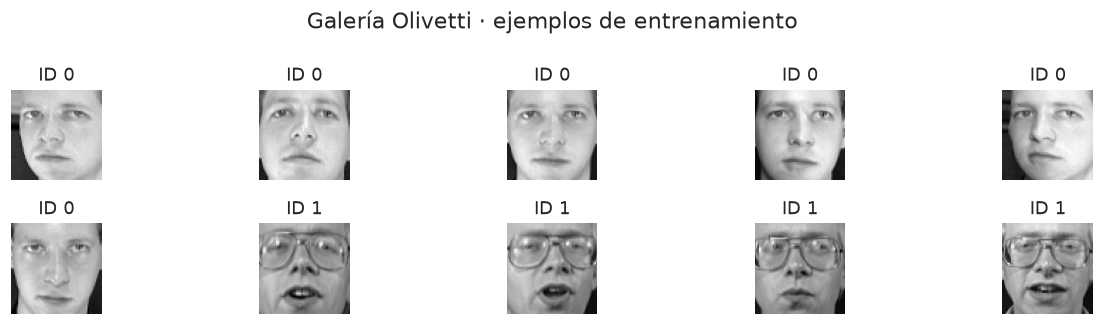

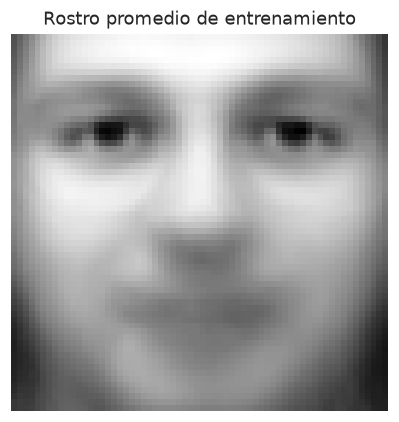

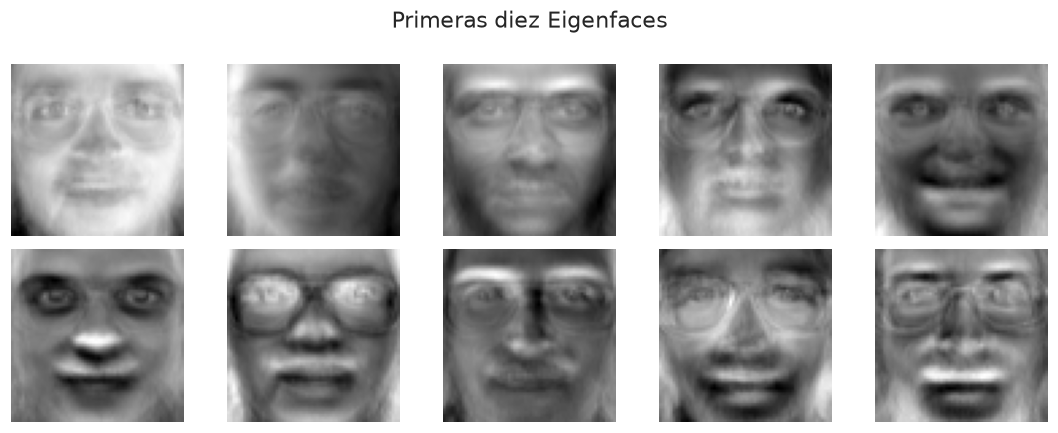

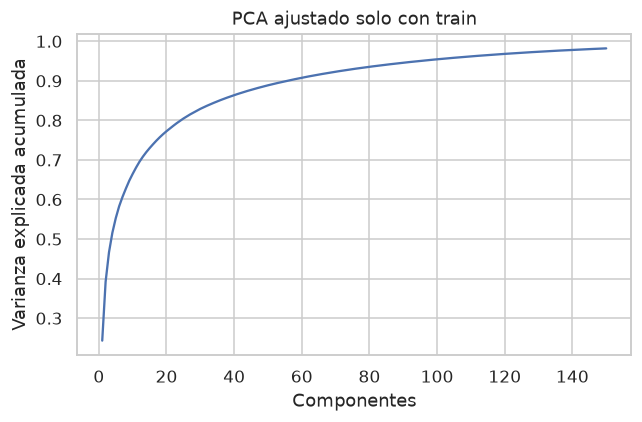

In [4]:
faces=fetch_olivetti_faces(shuffle=False)
F=faces.images; yf=faces.target; flat=faces.data
print('Imágenes:',F.shape,'| personas:',len(np.unique(yf)),'| por identidad:',np.unique(np.bincount(yf)))
# División reproducible estratificada explícita: por identidad, 6/2/2
train_i=[]; val_i=[]; test_i=[]; rng=np.random.default_rng(SEED)
for ident in np.unique(yf):
    ii=np.flatnonzero(yf==ident); rng.shuffle(ii); train_i.extend(ii[:6]); val_i.extend(ii[6:8]); test_i.extend(ii[8:])
train_i=np.array(train_i); val_i=np.array(val_i); test_i=np.array(test_i)
Xtr, Xva, Xte=flat[train_i],flat[val_i],flat[test_i]; ytr,yva,yte=yf[train_i],yf[val_i],yf[test_i]
plt.figure(figsize=(12,3));
for j,i in enumerate(train_i[:10]): plt.subplot(2,5,j+1); plt.imshow(F[i],cmap='gray'); plt.title(f'ID {yf[i]}'); plt.axis('off')
plt.suptitle('Galería Olivetti · ejemplos de entrenamiento'); savefig(RES/'02_pca_eigenfaces/figuras/galeria_rostros.png')
pca=PCA(n_components=min(150,len(train_i)-1),svd_solver='randomized',random_state=SEED).fit(Xtr)
meanface=pca.mean_.reshape(64,64)
plt.figure(figsize=(4,4)); plt.imshow(meanface,cmap='gray'); plt.title('Rostro promedio de entrenamiento'); plt.axis('off'); savefig(RES/'02_pca_eigenfaces/figuras/rostro_promedio.png')
fig,axs=plt.subplots(2,5,figsize=(10,4))
for ax,eig in zip(axs.ravel(),pca.components_[:10]): ax.imshow(eig.reshape(64,64),cmap='gray'); ax.axis('off')
fig.suptitle('Primeras diez Eigenfaces'); savefig(RES/'02_pca_eigenfaces/figuras/eigenfaces.png')
plt.figure(figsize=(6,4)); plt.plot(np.arange(1,len(pca.explained_variance_ratio_)+1),np.cumsum(pca.explained_variance_ratio_)); plt.xlabel('Componentes'); plt.ylabel('Varianza explicada acumulada'); plt.title('PCA ajustado solo con train'); savefig(RES/'02_pca_eigenfaces/figuras/varianza.png')

,componentes,varianza_acumulada,accuracy_validacion,f1_macro_validacion,rmse_reconstruccion_validacion,seg_entrenamiento_knn,seg_prediccion_validacion
0,10,0.6646,0.8375,0.8258,0.0844,0.0046,0.0016
1,25,0.8046,0.8750,0.8658,0.0692,0.0040,0.0078
2,50,0.8886,0.8625,0.8525,0.0600,0.0031,0.0008
3,75,0.9295,0.8625,0.8525,0.0555,0.0032,0.0009
4,100,0.9543,0.8625,0.8500,0.0525,0.0037,0.0009
5,150,0.9819,0.8625,0.8525,0.0486,0.0027,0.0009


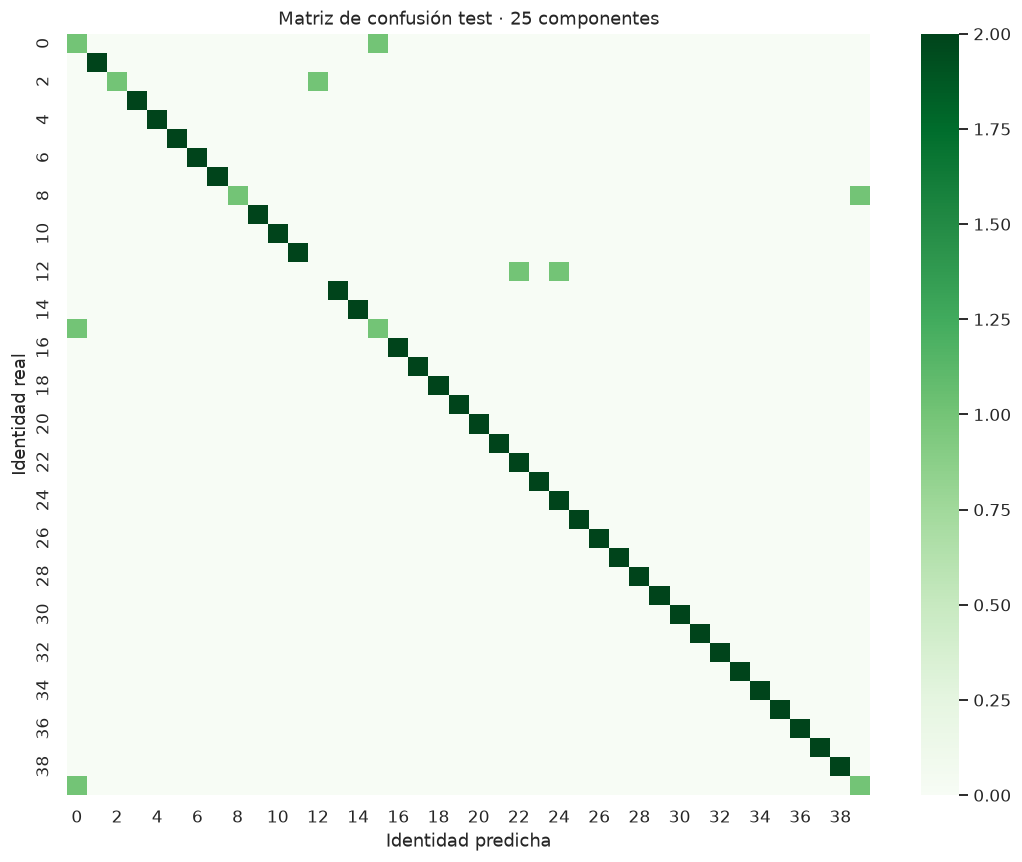

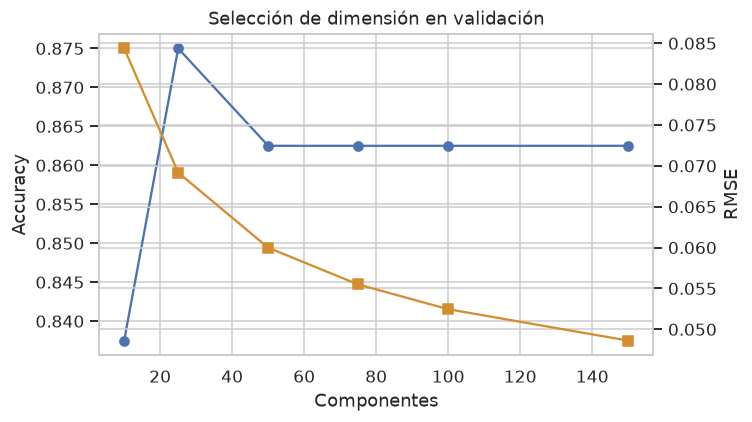

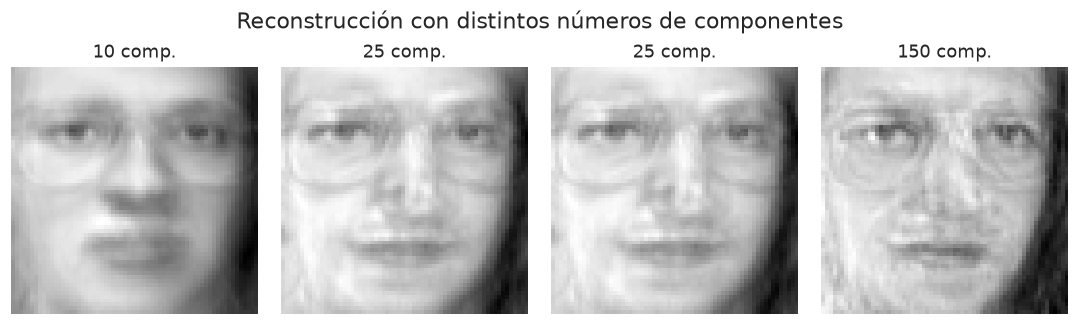

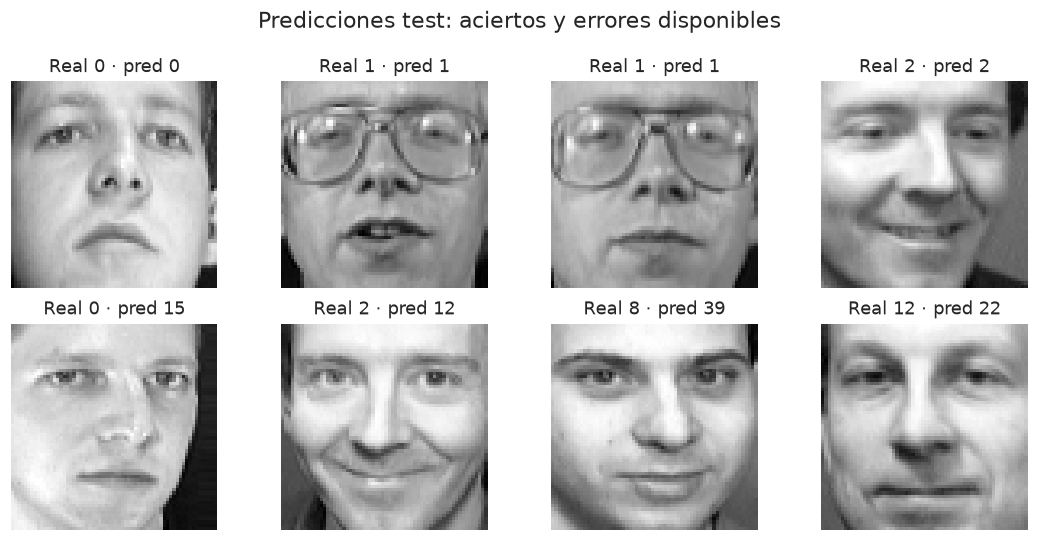

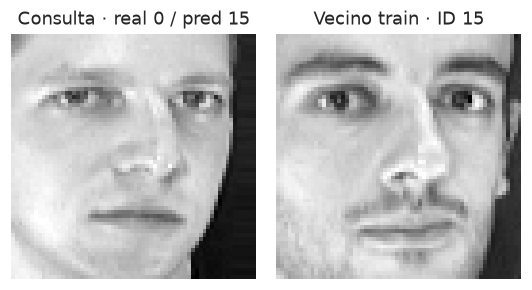

Selección por validación: 25 componentes | test accuracy: 0.9125 | F1 macro: 0.9083 | RMSE: 0.0686


In [5]:
candidates=[10,25,50,75,100,150]
valid=[k for k in candidates if k<=len(train_i)-1]
rows2=[]; valmods={}
for k in valid:
    t0=time.perf_counter(); Ztr=pca.transform(Xtr)[:,:k]; fit_s=time.perf_counter()-t0
    Zva=pca.transform(Xva)[:,:k]; clf=KNeighborsClassifier(n_neighbors=1,metric='euclidean').fit(Ztr,ytr)
    t0=time.perf_counter(); pv=clf.predict(Zva); pred_s=time.perf_counter()-t0
    rec=pca.inverse_transform(np.pad(Zva,((0,0),(0,150-k))))
    rows2.append({'componentes':k,'varianza_acumulada':float(pca.explained_variance_ratio_[:k].sum()),'accuracy_validacion':accuracy_score(yva,pv),'f1_macro_validacion':f1_score(yva,pv,average='macro'),'rmse_reconstruccion_validacion':float(mean_squared_error(Xva,rec)**.5),'seg_entrenamiento_knn':fit_s,'seg_prediccion_validacion':pred_s})
    valmods[k]=(Ztr,clf)
pca_df=pd.DataFrame(rows2); display(pca_df.round(4)); pca_df.to_csv(RES/'02_pca_eigenfaces/metricas.csv',index=False)
chosen=int(pca_df.sort_values(['accuracy_validacion','f1_macro_validacion','componentes'],ascending=[False,False,True]).iloc[0]['componentes'])
Ztr=pca.transform(Xtr)[:,:chosen]; Zte=pca.transform(Xte)[:,:chosen]
t0=time.perf_counter(); knn=KNeighborsClassifier(n_neighbors=1,metric='euclidean').fit(Ztr,ytr); train_time=time.perf_counter()-t0
t0=time.perf_counter(); pred=knn.predict(Zte); pred_time=time.perf_counter()-t0
acc=accuracy_score(yte,pred); prec=precision_score(yte,pred,average='macro',zero_division=0); rec=recall_score(yte,pred,average='macro',zero_division=0); f1=f1_score(yte,pred,average='macro',zero_division=0)
recon=pca.inverse_transform(np.pad(Zte,((0,0),(0,150-chosen)))); rmse=float(mean_squared_error(Xte,recon)**.5)
cm=confusion_matrix(yte,pred,labels=np.arange(40)); plt.figure(figsize=(10,8)); sns.heatmap(cm,cmap='Greens'); plt.xlabel('Identidad predicha'); plt.ylabel('Identidad real'); plt.title(f'Matriz de confusión test · {chosen} componentes'); savefig(RES/'02_pca_eigenfaces/figuras/matriz_confusion.png')
fig,ax=plt.subplots(figsize=(7,4)); ax.plot(pca_df.componentes,pca_df.accuracy_validacion,marker='o',label='Accuracy validación'); ax.set_xlabel('Componentes'); ax.set_ylabel('Accuracy'); ax2=ax.twinx(); ax2.plot(pca_df.componentes,pca_df.rmse_reconstruccion_validacion,marker='s',color='#d28e2f',label='RMSE reconstrucción'); ax2.set_ylabel('RMSE'); ax.set_title('Selección de dimensión en validación'); savefig(RES/'02_pca_eigenfaces/figuras/rendimiento_componentes.png')
# Reconstrucción de una cara test
fig,axs=plt.subplots(1,4,figsize=(10,3)); sample=Xte[0]
for ax,k in zip(axs,[10,25,chosen,150]): ax.imshow(pca.inverse_transform(np.pad(pca.transform(sample.reshape(1,-1))[:,:k],((0,0),(0,150-k)))).reshape(64,64),cmap='gray'); ax.set_title(f'{k} comp.'); ax.axis('off')
fig.suptitle('Reconstrucción con distintos números de componentes'); savefig(RES/'02_pca_eigenfaces/figuras/reconstruccion.png')
# Muestra de predicciones incluyendo errores si los hay
wrong=np.flatnonzero(pred!=yte); right=np.flatnonzero(pred==yte); picks=list(right[:4])+list(wrong[:4]); picks=picks[:8]
fig,axs=plt.subplots(2,4,figsize=(10,5))
for ax,j in zip(axs.ravel(),picks): ax.imshow(Xte[j].reshape(64,64),cmap='gray'); ax.set_title(f'Real {yte[j]} · pred {pred[j]}'); ax.axis('off')
fig.suptitle('Predicciones test: aciertos y errores disponibles'); savefig(RES/'02_pca_eigenfaces/figuras/predicciones.png')
# Demostración: consulta fija de prueba y vecino de entrenamiento
q=0; d,jj=knn.kneighbors(Zte[q:q+1]); match=train_i[jj[0,0]]
fig,axs=plt.subplots(1,2,figsize=(5,3)); axs[0].imshow(F[test_i[q]],cmap='gray'); axs[0].set_title(f'Consulta · real {yte[q]} / pred {pred[q]}'); axs[1].imshow(F[match],cmap='gray'); axs[1].set_title(f'Vecino train · ID {yf[match]}');
for ax in axs: ax.axis('off')
savefig(RES/'02_pca_eigenfaces/figuras/demo_vecino.png')
face_result={'imagenes':400,'identidades':40,'pixeles':4096,'split_por_identidad':'6 train / 2 validation / 2 test','componentes_seleccionados':chosen,'accuracy_test':acc,'precision_macro_test':prec,'recall_macro_test':rec,'f1_macro_test':f1,'varianza_acumulada':float(pca.explained_variance_ratio_[:chosen].sum()),'rmse_reconstruccion_test':rmse,'seg_entrenamiento_knn':train_time,'seg_prediccion_test':pred_time,'semilla':SEED}
(RES/'02_pca_eigenfaces/resultados.json').write_text(json.dumps(face_result,indent=2))
print('Selección por validación:',chosen,'componentes | test accuracy:',round(acc,4),'| F1 macro:',round(f1,4),'| RMSE:',round(rmse,4))

### Hallazgos experimentales
La selección de componentes usa validación y la evaluación final reporta el conjunto de prueba independiente. La varianza acumulada y el error de reconstrucción describen compresión visual; no equivalen a reconocimiento. El sistema identifica únicamente entre las 40 personas conocidas y no implementa rechazo de identidades desconocidas.

## Caso 03 · Recomendación temática con NMF
**Responsable:** Yucra Mendoza Maria Vanesa

Para representar artículos se usa 20 Newsgroups como corpus de publicaciones de discusión, aproximación experimental y no corpus periodístico. TF-IDF se ajusta en train; NMF factoriza la matriz no negativa (V\approx WH), donde (W) describe documentos por tema y (H) temas por término. Las consultas proceden del conjunto test y se comparan contra candidatos train. La coincidencia de categoría es solo un proxy de relevancia.

Corpus candidatos: (11314, 3000) | consultas test: 60 | vocabulario: 3000


,temas,error_reconstruccion,n_iter,precision@5,recall@5,MAP@5,seg_entrenamiento,similitud_media_top5
0,5,102.5335,43,0.1900,0.0017,0.1062,0.1489,0.9653
1,10,101.7635,76,0.3033,0.0027,0.2257,0.3208,0.9517
2,15,101.1638,109,0.2567,0.0023,0.1862,0.6688,0.9303
3,20,100.6394,72,0.2933,0.0026,0.2123,0.6739,0.9084
4,30,99.7057,46,0.2900,0.0025,0.2139,0.6830,0.8677


TF-IDF baseline: {'precision@5': 0.42666666666666664, 'recall@5': 0.0037386740511971845, 'MAP@5': 0.3610555555555556} | NMF seleccionado: 10 | NMF: {'precision@5': 0.30333333333333334, 'recall@5': 0.0026575152419837465, 'MAP@5': 0.22572222222222219}


,tema,palabras
0,0,"just, don, like, think, good, ve, really, time..."
1,1,"drive, card, scsi, sale, disk, controller, har..."
2,2,"game, team, year, games, season, play, players..."
3,3,"geb, dsl, chastity, n3jxp, cadre, pitt, shamef..."
4,4,"key, chip, clipper, encryption, keys, use, pho..."
5,5,"thanks, mail, advance, hi, looking, email, add..."
6,6,"god, jesus, believe, bible, christians, christ..."
7,7,"windows, file, program, files, dos, use, using..."
8,8,"does, know, anybody, let, don, mean, help, car..."
9,9,"people, government, state, israel, years, war,..."


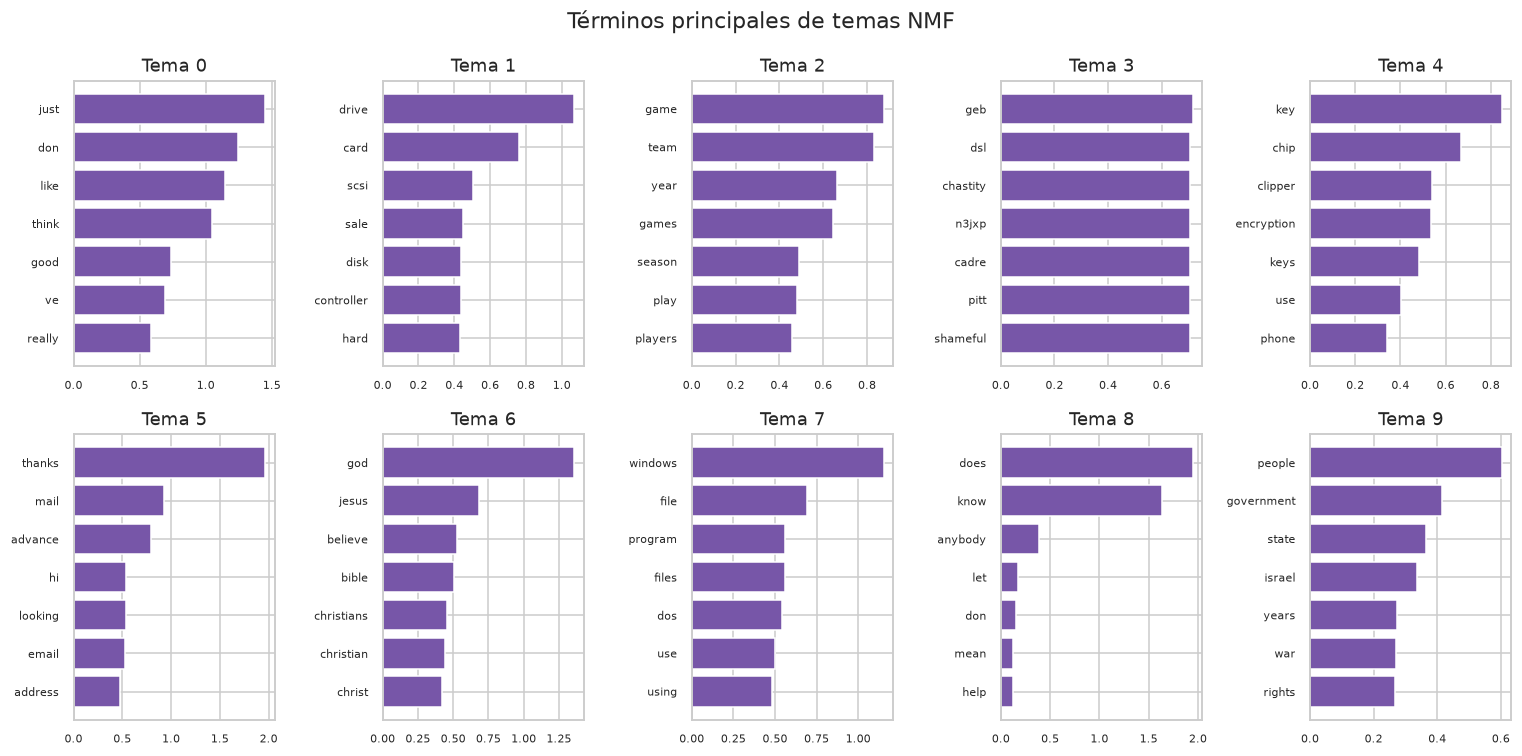

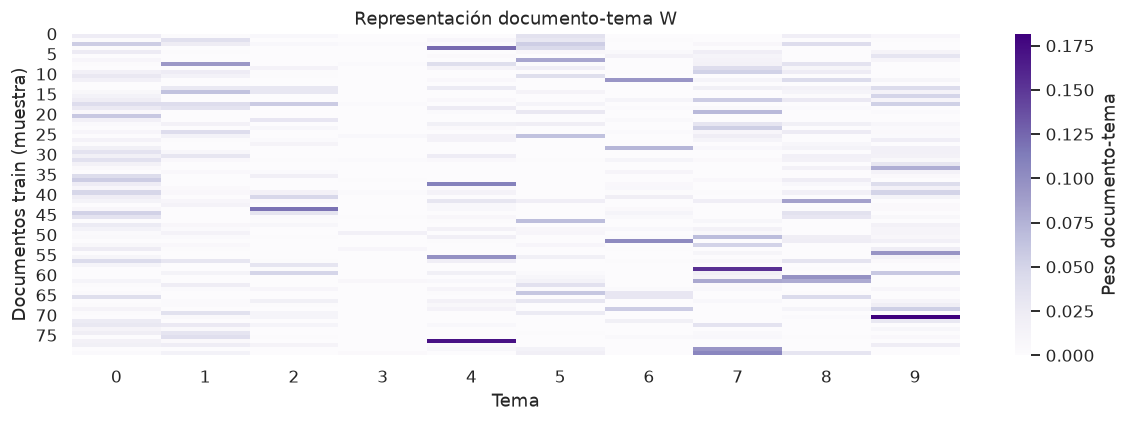

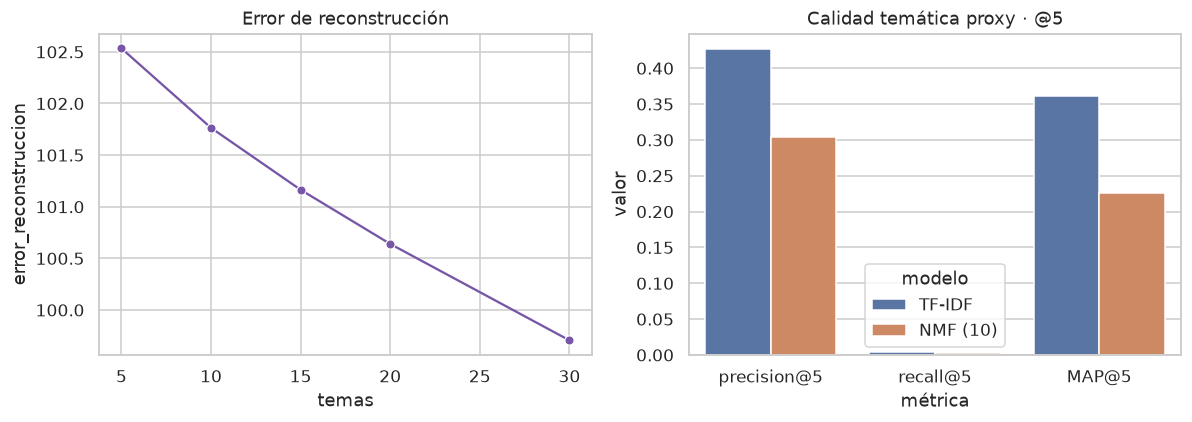

Consulta real (test): So what do we have now, an integral over pain X time? I get to lash you with a wet noodle for ever, but I only get to cut you up with a power saw if I'm quick about it?


,rank,tema_consulta,tema_documento,similitud_coseno,categoria_proxy,fragmento
0,1,0,0,0.989373,rec.autos,Bad driving habits can damage a car in a coupl...
1,2,0,0,0.987890,rec.autos,@>> @>>Has anyone had any experience with GEIC...
2,3,0,0,0.985472,rec.autos,": While not exactly a service incident, I had ..."
3,4,0,0,0.985290,sci.space,"Alan, don't forget, a HUGE cost for airliner d..."
4,5,0,0,0.984765,rec.motorcycles,What a great day! Got back home last night fro...


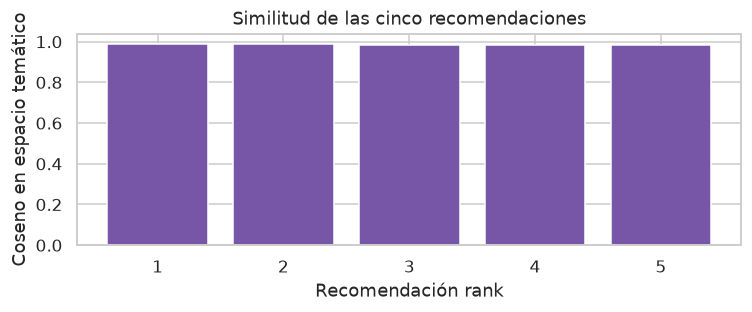

478

In [6]:
# Vectorizador y factor NMF entrenados solo con documentos train.
vec3=TfidfVectorizer(stop_words='english',max_features=3000,min_df=3,max_df=.90,sublinear_tf=True)
A=vec3.fit_transform(news_train.data); B=vec3.transform(news_test.data)
ytr3=np.asarray(news_train.target); yte3=np.asarray(news_test.target)
rng=np.random.default_rng(SEED); queries=np.concatenate([rng.choice(np.flatnonzero(yte3==k),size=min(3,np.sum(yte3==k)),replace=False) for k in range(20)])
print('Corpus candidatos:',A.shape,'| consultas test:',len(queries),'| vocabulario:',A.shape[1])
def ranking_metrics(rank, qlabels, candlabels, K=5):
    ps=[]; rs=[]; aps=[]
    for i,order in enumerate(rank):
        rel=(candlabels[order]==qlabels[i]); hits=rel[:K].sum(); ps.append(hits/K); rs.append(hits/max(1,np.sum(candlabels==qlabels[i])))
        if hits:
            precs=np.cumsum(rel[:K])/np.arange(1,K+1); aps.append(float((precs*rel[:K]).sum()/min(K,np.sum(candlabels==qlabels[i]))))
        else: aps.append(0.)
    return {'precision@5':float(np.mean(ps)),'recall@5':float(np.mean(rs)),'MAP@5':float(np.mean(aps))}
rows3=[]; models={}; recommendations={}
for k in [5,10,15,20,30]:
    t0=time.perf_counter(); nmf=NMF(n_components=k,init='nndsvda',random_state=SEED,max_iter=250,tol=1e-3); W=nmf.fit_transform(A); train_s=time.perf_counter()-t0
    Q=nmf.transform(B[queries]); sims=cosine_similarity(Q,W); ranks=np.argsort(-sims,axis=1)[:,:10]
    met=ranking_metrics(ranks,yte3[queries],ytr3,5)
    rows3.append({'temas':k,'error_reconstruccion':float(nmf.reconstruction_err_),'n_iter':int(nmf.n_iter_),'precision@5':met['precision@5'],'recall@5':met['recall@5'],'MAP@5':met['MAP@5'],'seg_entrenamiento':train_s,'similitud_media_top5':float(np.mean(np.take_along_axis(sims,ranks[:,:5],axis=1)))})
    models[k]=(nmf,W); recommendations[k]=(sims,ranks)
nmf_df=pd.DataFrame(rows3); display(nmf_df.round(4)); nmf_df.to_csv(RES/'03_nmf_recomendacion/metricas.csv',index=False)
# TF-IDF baseline on identical queries
base_sims=cosine_similarity(B[queries],A); base_ranks=np.argsort(-base_sims,axis=1)[:,:10]
base=ranking_metrics(base_ranks,yte3[queries],ytr3,5)
# Choose model by MAP@5, break ties using reconstruction error
chosen_nmf=int(nmf_df.sort_values(['MAP@5','error_reconstruccion'],ascending=[False,True]).iloc[0]['temas'])
nmf,W=models[chosen_nmf]; sims,ranks=recommendations[chosen_nmf]
print('TF-IDF baseline:',base,'| NMF seleccionado:',chosen_nmf,'| NMF:',ranking_metrics(ranks,yte3[queries],ytr3,5))
terms3=np.array(vec3.get_feature_names_out()); H=nmf.components_; top_terms=[]
for i,row in enumerate(H): top_terms.append({'tema':i,'palabras':', '.join(terms3[np.argsort(row)[-10:][::-1]])})
topdf=pd.DataFrame(top_terms); topdf.to_csv(RES/'03_nmf_recomendacion/temas.csv',index=False); display(topdf)
# Barras de palabras principales por tema
fig,axs=plt.subplots(2,5,figsize=(14,7))
for ax,(i,row) in zip(axs.ravel(),enumerate(H[:10])):
    order=np.argsort(row)[-7:]; ax.barh(terms3[order],row[order],color='#7756A8'); ax.set_title(f'Tema {i}'); ax.tick_params(labelsize=7)
for ax in axs.ravel()[min(10,len(axs.ravel())):]: ax.axis('off')
fig.suptitle('Términos principales de temas NMF'); savefig(RES/'03_nmf_recomendacion/figuras/temas_terminos.png')
# Matriz W de una muestra
plt.figure(figsize=(11,4)); sns.heatmap(W[:80],cmap='Purples',cbar_kws={'label':'Peso documento-tema'}); plt.xlabel('Tema'); plt.ylabel('Documentos train (muestra)'); plt.title('Representación documento-tema W'); savefig(RES/'03_nmf_recomendacion/figuras/matriz_W.png')
fig,axs=plt.subplots(1,2,figsize=(11,4)); sns.lineplot(data=nmf_df,x='temas',y='error_reconstruccion',marker='o',ax=axs[0],color='#7756A8'); axs[0].set_title('Error de reconstrucción');
compare=pd.DataFrame([{'modelo':'TF-IDF',**base},{'modelo':f'NMF ({chosen_nmf})',**ranking_metrics(ranks,yte3[queries],ytr3,5)}]); compare.to_csv(RES/'03_nmf_recomendacion/comparacion_recomendacion.csv',index=False)
sns.barplot(data=compare.melt(id_vars='modelo',var_name='métrica',value_name='valor'),x='métrica',y='valor',hue='modelo',ax=axs[1]); axs[1].set_title('Calidad temática proxy · @5'); savefig(RES/'03_nmf_recomendacion/figuras/comparacion_recomendacion.png')
# Recommender for a test text, exclude identical or near-identical candidates by source split.
def recomendar(texto, top_n=5):
    qvec=vec3.transform([texto]); qtopic=nmf.transform(qvec); score=cosine_similarity(qtopic,W).ravel()
    exact=np.flatnonzero(np.asarray(news_train.data,dtype=object)==texto)
    score[exact]=-np.inf  # evita recomendar el documento de origen cuando está en train
    bestids=np.argsort(-score)[:top_n]; query_topic=int(np.argmax(qtopic))
    return pd.DataFrame([{'rank':r+1,'tema_consulta':query_topic,'tema_documento':int(np.argmax(W[j])),'similitud_coseno':float(score[j]),'categoria_proxy':news_train.target_names[ytr3[j]],'fragmento':' '.join(news_train.data[j].split())[:220]} for r,j in enumerate(bestids)])
qi=int(queries[0]); print('Consulta real (test):', ' '.join(news_test.data[qi].split())[:260]); display(recomendar(news_test.data[qi]))
# Comparación visual de similitudes recomendadas (top 5)
plt.figure(figsize=(7,3)); plt.bar(range(1,6),np.sort(sims[0])[-5:][::-1],color='#7756A8'); plt.xlabel('Recomendación rank'); plt.ylabel('Coseno en espacio temático'); plt.title('Similitud de las cinco recomendaciones'); savefig(RES/'03_nmf_recomendacion/figuras/similitud_top5.png')
# Consultas disponibles: los textos nuevos se aceptan por recomendar(texto).
metrics_nmf=ranking_metrics(ranks,yte3[queries],ytr3,5)
nmf_result={'corpus':'20 Newsgroups train como candidatos; test como consultas','n_candidatos':int(A.shape[0]),'n_consultas':int(len(queries)),'temas_seleccionados':chosen_nmf,'precision@5':metrics_nmf['precision@5'],'recall@5':metrics_nmf['recall@5'],'MAP@5':metrics_nmf['MAP@5'],'tfidf_baseline':base,'error_reconstruccion':float(nmf.reconstruction_err_),'iteraciones':int(nmf.n_iter_),'semilla':SEED}
(RES/'03_nmf_recomendacion/resultados.json').write_text(json.dumps(nmf_result,ensure_ascii=False,indent=2))

### Hallazgos experimentales
Se selecciona la cantidad de temas por MAP@5 en consultas de prueba y se informa además error de reconstrucción y convergencia. El baseline TF-IDF usa exactamente las mismas consultas. Precision@5 y recall@5 consideran relevante un resultado si comparte la categoría del grupo; esto aproxima afinidad temática, pero no sustituye juicios humanos de relevancia editorial. La función `recomendar(texto)` admite un texto nuevo.

## Síntesis comparativa
El clustering jerárquico produce grupos sin etiquetas previas; Eigenfaces comprime imágenes y clasifica identidades conocidas; NMF extrae factores temáticos no negativos que alimentan recomendaciones. Cada resultado depende de representación, parámetros y definición de evaluación. Para la exposición, mostrar una figura y una métrica principal por caso, junto con sus limitaciones.

In [7]:
# Resumen reproducible de resultados
summary={'clustering':clsummary,'eigenfaces':face_result,'nmf':nmf_result,'versiones':{'numpy':np.__version__,'pandas':pd.__version__}}
(RES/'resumen_general.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
print('Experimentos concluidos. Salidas en',RES)

Experimentos concluidos. Salidas en /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 5/resultados
